In [1]:
import cv2
import numpy as np
import glob
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from moviepy.editor import *

In [2]:
raw_dir = glob.glob('./stim/raw_extracts/*')
processed_dir = glob.glob('./stim/processed_extracts')

In [3]:
def get_stim(stim_type):
    stim = []
    for dir in raw_dir:
        if len(glob.glob(f'{dir}/*_{stim_type}_*.mov')) != 0:
            stim.append(glob.glob(f'{dir}/*_{stim_type}_*.mov'))

    return stim


def get_info(filename):
    info = []
    
    dyad = int(filename.split(os.sep)[1])
    info.append(dyad)
    extract = int(filename.split(os.sep)[2].split('_')[1])
    info.append(extract)
    speaker = filename.split(os.sep)[2].split('_')[-1][:1]
    info.append(speaker)

    video = cv2.VideoCapture(filename)
    fps = video.get(cv2.CAP_PROP_FPS)
    frame_count = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
    info.append(np.round(frame_count/fps))

    m = filename[0:-9]+'M.mov'
    info.append(m)
    f = filename[0:-9]+'F.mov'
    info.append(f)

    if glob.glob(f'./stim/processed_extracts/true/{dyad}/{extract}_*.mov'):
        info.append('true')    
    elif glob.glob(f'./stim/processed_extracts/fake/{dyad}/{extract}_*_*.mov') or glob.glob(f'./stim/processed_extracts/fake/{dyad}/*_{extract}_*.mov'):
        info.append('fake')
    elif glob.glob(f'./stim/processed_extracts/fake_ad/*/{dyad}_{extract}_*_*_*.mov') or glob.glob(f'./stim/processed_extracts/fake_ad/*/*_*_{dyad}_{extract}_*.mov'):
        info.append('fake_ad')
    else:
        info.append('')
    
    
    return info


df = pd.DataFrame(columns=['dyad', 'extract', 'speaker', 'duration', 'm', 'f', 'used'])

stim_list = get_stim('all')
flat_list = [item for sublist in stim_list for item in sublist]
for i in range(len(flat_list)):
    df.loc[i] = get_info(flat_list[i])

In [4]:
df

,dyad,extract,speaker,duration,m,f,used
0,1,1,M,17.0,./stim/raw_extracts\1\1_1_M.mov,./stim/raw_extracts\1\1_1_F.mov,fake
1,1,2,M,17.0,./stim/raw_extracts\1\1_2_M.mov,./stim/raw_extracts\1\1_2_F.mov,fake
2,1,3,F,26.0,./stim/raw_extracts\1\1_3_M.mov,./stim/raw_extracts\1\1_3_F.mov,true
3,1,4,F,17.0,./stim/raw_extracts\1\1_4_M.mov,./stim/raw_extracts\1\1_4_F.mov,fake_ad
4,1,5,F,12.0,./stim/raw_extracts\1\1_5_M.mov,./stim/raw_extracts\1\1_5_F.mov,
...,...,...,...,...,...,...,...
300,8,5,F,10.0,./stim/raw_extracts\8\8_5_M.mov,./stim/raw_extracts\8\8_5_F.mov,fake
301,8,6,F,12.0,./stim/raw_extracts\8\8_6_M.mov,./stim/raw_extracts\8\8_6_F.mov,fake_ad
302,9,1,F,10.0,./stim/raw_extracts\9\9_1_M.mov,./stim/raw_extracts\9\9_1_F.mov,fake
303,9,2,M,6.0,./stim/raw_extracts\9\9_2_M.mov,./stim/raw_extracts\9\9_2_F.mov,true


In [5]:
print('Total extracts:', len(df))
print('Total Male extracts:', len(df[df['speaker'] == 'M']))
print('Total Female extracts:', len(df[df['speaker'] == 'F']))

Total extracts: 305
Total Male extracts: 173
Total Female extracts: 132


In [6]:
print('Used extracts:', len(df[(df['used'] != '')]))
print('Used Male extracts:', len(df[(df['used'] != '') & (df['speaker'] == 'M')]))
print('Used Female extracts', len(df[(df['used'] != '') & (df['speaker'] == 'F')]))
print('Remaining extracts:', len(df[(df['used'] == '')]))

Used extracts: 300
Used Male extracts: 170
Used Female extracts 130
Remaining extracts: 5


In [7]:
print('True trials:', len(df[df['used'] == 'true']))
print('Fake trials (within-dyad):', int(len(df[df['used'] == 'fake'])))
print('Fake trials (across-dyad):', int(len(df[df['used'] == 'fake_ad'])))

True trials: 100
Fake trials (within-dyad): 102
Fake trials (across-dyad): 98


In [8]:
print('Male True:', len(df[(df['used'] == 'true') & (df['speaker'] == 'M')]))
print('Female True:', len(df[(df['used'] == 'true') & (df['speaker'] == 'F')]))

print('Male Fake (within-dyad):', int(len(df[(df['used'] == 'fake') & (df['speaker'] == 'M')])/2))
print('Female Fake (within-dyad):', int(len(df[(df['used'] == 'fake') & (df['speaker'] == 'F')])/2))

print('Male Fake (across-dyad):', int(len(df[(df['used'] == 'fake_ad') & (df['speaker'] == 'M')])/2))
print('Female Fake (across-dyad):', int(len(df[(df['used'] == 'fake_ad') & (df['speaker'] == 'F')])/2))

Male True: 56
Female True: 44
Male Fake (within-dyad): 28
Female Fake (within-dyad): 23
Male Fake (across-dyad): 29
Female Fake (across-dyad): 20


<Axes: xlabel='used', ylabel='duration'>

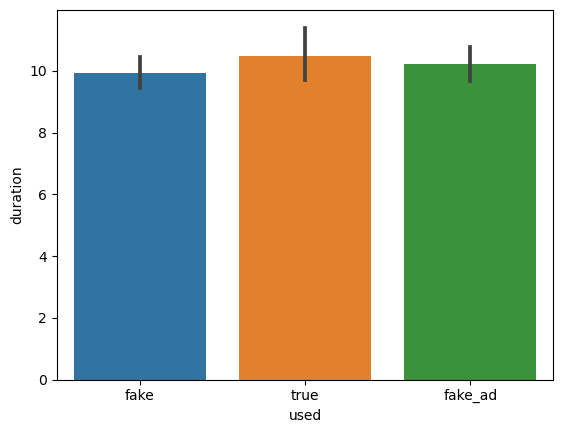

In [9]:
sns.barplot(df[df['used'] != ''], x="used", y='duration')

In [10]:
df[df['used'] == '']

,dyad,extract,speaker,duration,m,f,used
4,1,5,F,12.0,./stim/raw_extracts\1\1_5_M.mov,./stim/raw_extracts\1\1_5_F.mov,
62,20,1,F,5.0,./stim/raw_extracts\20\20_1_M.mov,./stim/raw_extracts\20\20_1_F.mov,
89,27,5,M,18.0,./stim/raw_extracts\27\27_5_M.mov,./stim/raw_extracts\27\27_5_F.mov,
180,40,9,M,8.0,./stim/raw_extracts\40\40_9_M.mov,./stim/raw_extracts\40\40_9_F.mov,
192,43,5,M,12.0,./stim/raw_extracts\43\43_5_M.mov,./stim/raw_extracts\43\43_5_F.mov,


In [ ]:
# trials = glob.glob('./stim/processed_extracts/practice/*.mov')

# for i in range(1, 61):
#     os.makedirs(f'./stim/processed_extracts/audio/{i}', exist_ok=True)

# for trial in trials:
#     root = './stim/processed_extracts/practice/'
#     dyad = trial.split(os.sep)[-2:-1][0]
#     file = trial.split(os.sep)[-1][:-7]+'audio.wav'
#     clip = VideoFileClip(trial)
#     clip.audio.write_audiofile(os.path.join(root, dyad file), codec='pcm_s32le')